In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

In [4]:
X_train = np.load("../dataset/sample_data/X_train.npy")
y_train = np.load("../dataset/sample_data/y_train.npy")

X_test = np.load("../dataset/sample_data/X_test.npy")
y_test = np.load("../dataset/sample_data/y_test.npy")

print("Train shape:",X_train.shape)
print("Test shape:",X_test.shape)

Train shape: (34750, 12)
Test shape: (8688, 12)


In [5]:
model = Sequential()

model.add(Dense(32,activation="relu",input_shape=(12,)))
model.add(Dropout(0.2))

model.add(Dense(16,activation="relu"))

model.add(Dense(4,activation="softmax"))

model.summary()

c:\Users\kampe\Desktop\radar_fpga_ml\venv\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,012 (3.95 KB)

 Trainable params: 1,012 (3.95 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/30
435/435 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8056 - loss: 0.4910 - val_accuracy: 0.9256 - val_loss: 0.1997
Epoch 2/30
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9121 - loss: 0.2045 - val_accuracy: 0.9318 - val_loss: 0.1618
Epoch 3/30
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9209 - loss: 0.1759 - val_accuracy: 0.9322 - val_loss: 0.1540
Epoch 4/30
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9287 - loss: 0.1619 - val_accuracy: 0.9341 - val_loss: 0.1484
Epoch 5/30
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9303 - loss: 0.1548 - val_accuracy: 0.9332 - val_loss: 0.1448
Epoch 6/30
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9308 - loss: 0.1511 - val_accuracy: 0.9370 - val_loss: 0.1417
Epoch 7/30
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9329 - loss: 0.1477 - val_accuracy: 0.9370 - val_loss: 0.1401
Epoch 8/30
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9321 - loss: 0.1460 - val_accuracy: 0.

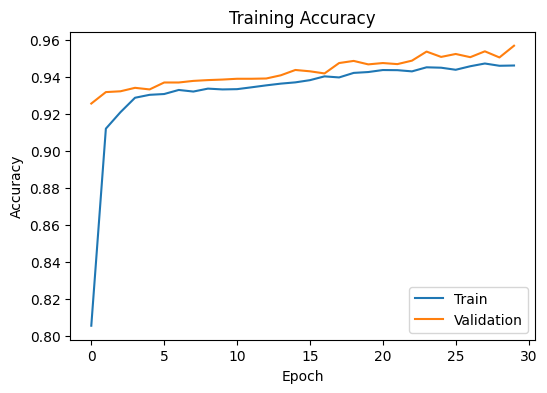

In [8]:
plt.figure(figsize=(6,4))

plt.plot(history.history["accuracy"],label="Train")
plt.plot(history.history["val_accuracy"],label="Validation")

plt.title("Training Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()

plt.show()

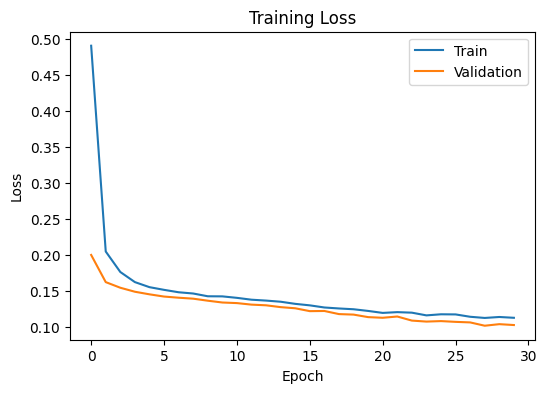

In [9]:
plt.figure(figsize=(6,4))

plt.plot(history.history["loss"],label="Train")
plt.plot(history.history["val_loss"],label="Validation")

plt.title("Training Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()

plt.show()

In [10]:
predictions = model.predict(X_test)

y_pred = np.argmax(predictions,axis=1)

acc = accuracy_score(y_test,y_pred)

print("Test Accuracy:",acc)

272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Test Accuracy: 0.9571823204419889


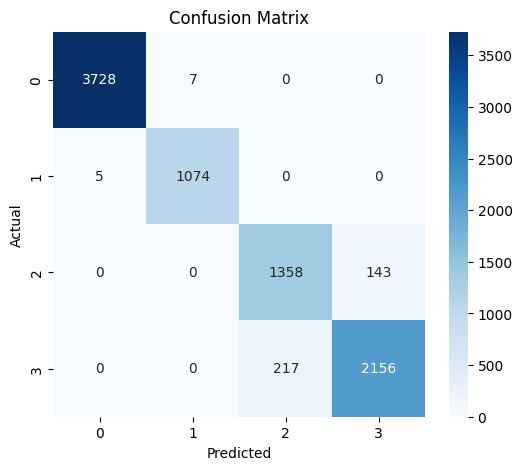

In [11]:
cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [12]:
target_names = [
    "benign",
    "constant_jammer",
    "random_jammer",
    "reactive_jammer"
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=target_names
    )
)

                 precision    recall  f1-score   support

         benign       1.00      1.00      1.00      3735
constant_jammer       0.99      1.00      0.99      1079
  random_jammer       0.86      0.90      0.88      1501
reactive_jammer       0.94      0.91      0.92      2373

       accuracy                           0.96      8688
      macro avg       0.95      0.95      0.95      8688
   weighted avg       0.96      0.96      0.96      8688



In [13]:
model.save("../models/jamshield_model.h5")

print("Model saved")

Model saved


In [17]:
weights = model.get_weights()

weights_obj = np.array(weights, dtype=object)

np.save("../model/weights/model_weights.npy", weights_obj, allow_pickle=True)

print("Weights exported successfully")

Weights exported successfully


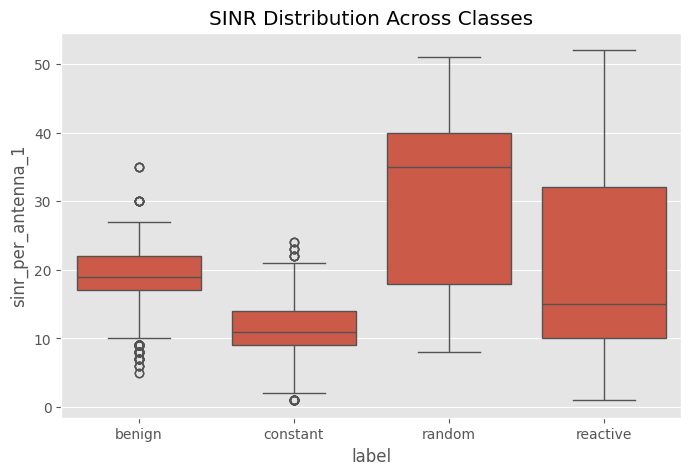

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x="label", y="sinr_per_antenna_1", data=dataset)

plt.title("SINR Distribution Across Classes")

plt.show()